#Connect to Drive

In [1]:
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


#Unzip data

In [ ]:
!cp gdrive/My\ Drive/MASTER_2024_2025/DOG_WOLF.zip /content/
!unzip DOG_WOLF.zip -d DATI/

#Import

In [3]:
###########################
# IMPORT
import scipy.io as sio
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim import lr_scheduler
import numpy as np
import torchvision
from torchvision import datasets, models, transforms
import matplotlib.pyplot as plt
import time
import os
import shutil
import copy
import random
from random import shuffle
import matplotlib.pyplot as plt
######################################

#Check device


In [4]:
print(torch.__version__)
print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0))
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(device)

2.6.0+cu124
True
Tesla T4
cuda:0


# Create train - test- val

In [5]:
def split_train_val_test(list_files, percentage_train):
  shuffle(list_files)
  n_train = int(len(list_files)*percentage_train)
  n_remain = len(list_files) - n_train
  val_test = int(n_remain/2)

  train_files = list_files[:n_train]
  remain = list_files[n_train:]

  val_files = remain[:val_test]
  test_files = remain[val_test:]

  return train_files, val_files, test_files



basePath = '/content/DATI/DOG_WOLF/data/'

list_dogs = os.listdir(basePath + 'dogs/')
list_wolves = os.listdir(basePath + 'wolves/')

percentage_train = 0.8
train_files_dogs, val_files_dogs, test_files_dogs = split_train_val_test(list_dogs, percentage_train)
train_files_wolves, val_files_wolves, test_files_wolves = split_train_val_test(list_wolves, percentage_train)

outPath = '/content/DATI/SplitDog_wolf/data/'
path_train_dogs =  outPath + 'train/dogs/'
path_val_dogs =  outPath + 'val/dogs/'

path_train_wolves =  outPath + 'train/wolves/'
path_val_wolves =  outPath + 'val/wolves/'

path_test =  outPath + 'test/'

try:
  os.makedirs(path_train_dogs)
  os.makedirs(path_val_dogs)
  os.makedirs(path_train_wolves)
  os.makedirs(path_val_wolves)
  os.makedirs(path_test)
except:
  pass

for file in train_files_dogs:
  shutil.copyfile(basePath + 'dogs/' + file, path_train_dogs + file)

for file in train_files_wolves:
  shutil.copyfile(basePath + 'wolves/' + file, path_train_wolves + file)

for file in val_files_dogs:
  shutil.copyfile(basePath + 'dogs/' + file, path_val_dogs + file)

for file in val_files_wolves:
  shutil.copyfile(basePath + 'wolves/' + file, path_val_wolves + file)


list_classes = []
for file in test_files_dogs:
  shutil.copyfile(basePath + 'dogs/' + file, path_test + file)
  list_classes.append('dogs')

for file in test_files_wolves:
  shutil.copyfile(basePath + 'wolves/' + file, path_test + file)
  list_classes.append('wolves')

test_file = pd.DataFrame()
test_file['files'] = test_files_dogs + test_files_wolves
test_file['label'] = list_classes

test_file.to_csv('testLabels.csv', index = False)

#Functions definition

 *train_model* is an example for training a neural network





In [33]:
#find best model on validation test
def train_loop_validation(dataloaders, startEpoch, numEpochs, model_conv, criterionCNN, optimizer_conv,
                          best_acc, best_loss, best_epoca, outputPath):

  for epochs in range(startEpoch, numEpochs + 1):
    since = time.time()

    modelLoss_train = 0.0
    modelAcc_train = 0.0

    model_conv.train()

    totalSize = 0


    #for each batch
    for inputs, labels in dataloaders['train']:
      inputs = inputs.type(torch.FloatTensor).cuda()
      labels = labels.cuda()

      optimizer_conv.zero_grad()
      model_conv.zero_grad()

      y = model_conv(inputs)  #batch input alla rete  BXCX224X224 -> y è il vettore dei valori predetti
      outp, preds = torch.max(y, 1)

      lossCNN = criterionCNN(y, labels) #average for each batch

      modelLoss_train += lossCNN.item() * inputs.size(0)
      totalSize += inputs.size(0)
      modelAcc_train += torch.sum(preds == labels.data).item()

      lossCNN.backward()  # pred = f(x)   -> loss = L(f(x), l_true)
      optimizer_conv.step()


    modelLoss_epoch_train = modelLoss_train/totalSize
    modelAcc_epoch_train  = modelAcc_train/totalSize

    #save the weights of the network
    torch.save(model_conv.state_dict(), outputPath + 'train_weights.pth')

    model_conv.eval()
    totalSize_val = 0
    modelLoss_val = 0.0
    modelAcc_val = 0.0

    for inputs, labels in dataloaders['val']:
      inputs = inputs.type(torch.FloatTensor).cuda()
      labels = labels.cuda()

      y = model_conv(inputs)
      outp, preds = torch.max(y, 1)
      lossCNN = criterionCNN(y, labels)

      modelLoss_val += lossCNN.item() * inputs.size(0)
      totalSize_val += inputs.size(0)
      modelAcc_val += torch.sum(preds == labels.data).item()


    modelLoss_epoch_val=modelLoss_val/totalSize_val
    modelAcc_epoch_val = modelAcc_val/totalSize_val
    time_elapsed = time.time()-since

    #print(time_elapsed)
    print('[Epoch %d][TRAIN on %d [Loss: %.4f  ACC: %.4f]][VAL on %d [Loss: %.4f  ACC: %.4f]][TIME: %.0f m %.0f s]'
          %(epochs, totalSize, modelLoss_epoch_train, modelAcc_epoch_train, totalSize_val, modelLoss_epoch_val,
            modelAcc_epoch_val, time_elapsed // 60, time_elapsed % 60))

    #if epochs == 1 or modelLoss_epoch_val < best_loss:
    if (modelAcc_epoch_val > best_acc) or (modelAcc_epoch_val == best_acc and modelLoss_epoch_val < best_loss) :
      print('     .... Saving best weights ....')
      best_acc = modelAcc_epoch_val
      best_loss = modelLoss_epoch_val
      best_epoca = epochs
      #salvataggio dei migliori pesi sul validation
      torch.save(model_conv.state_dict(), outputPath + 'best_model_weights.pth')

    with open(outputPath + 'lossTrain.txt', "a") as file_object:
      file_object.write(str(modelLoss_epoch_train) +'\n')

    with open(outputPath + 'AccTrain.txt', "a") as file_object:
      file_object.write(str(modelAcc_epoch_train)+'\n')

    with open(outputPath + 'lossVal.txt', "a") as file_object:
      file_object.write(str(modelLoss_epoch_val)+'\n')

    with open(outputPath + 'AccVal.txt', "a") as file_object:
      file_object.write(str(modelAcc_epoch_val)+'\n')

    sio.savemat(outputPath + 'check_point.mat', {'best_acc': best_acc,
                                                 'best_loss': best_loss,
                                                 'best_epoca': best_epoca,
                                                 'last_epoch': epochs})

#Hyper-parameters

In [26]:
#rendere l'esecuzione deterministica
torch.manual_seed(0)
np.random.seed(0)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False


learning_rate = 0.00001
batch_size = 16
set_classes_number = 2
num_epoch = 100

#Load Data

In [27]:
data_transforms = {
    'train': transforms.Compose([
        transforms.RandomResizedCrop(224),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
    'val': transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
}


data_dir = '/content/DATI/SplitDog_wolf/data/'
#data_transforms['train']
appoggio = datasets.ImageFolder(os.path.join(data_dir, 'train'), data_transforms['train'])
appoggio.samples[1000]
appoggio.classes

image_datasets = {x: datasets.ImageFolder(os.path.join(data_dir, x),data_transforms[x]) for x in ['train', 'val']}
dataloaders = {x: torch.utils.data.DataLoader(image_datasets[x], batch_size=batch_size, shuffle=True, num_workers=4) for x in ['train', 'val']}


dataset_sizes = {x: len(image_datasets[x]) for x in ['train', 'val']}
class_names = image_datasets['train'].classes

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
class_names = (image_datasets['train'].classes)
print(class_names)
print(image_datasets['val'].classes)

['dogs', 'wolves']
['dogs', 'wolves']


/usr/local/lib/python3.11/dist-packages/torch/utils/data/dataloader.py:624: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(


In [ ]:
img, cl = appoggio.__getitem__(1000)

print(img.shape)

plt.imshow(img.permute([1,2,0]))
plt.show()

''''
for x,y in dataloaders['train']:
  print(x.shape)
  print(y.shape)
'''

#Train model

In [34]:
# -------------------------------------------------------------------------------------  create model
networkName = 'alexnet16_onlyLast_2'
WeightPath = '/content/gdrive/My Drive/Esercitazioni_ML_24_25/' + networkName + '/'

try:
  os.makedirs(WeightPath)
except:
  pass

'''
model_ft = models.resnet18(pretrained=True)
num_ftrs = model_ft.fc.in_features
# Here the size of each output sample is set to 2.
# Alternatively, it can be generalized to nn.Linear(num_ftrs, len(class_names)).
model_ft.fc = nn.Linear(num_ftrs, 2)

for param in model_ft.parameters():
  param.requires_grad = True
'''

model_ft = torchvision.models.alexnet(pretrained=True)
# change last fully connected layer
model_ft.classifier[6] = nn.Linear(4096, set_classes_number)

# set requires_grad=false
for param in model_ft.parameters():
  param.requires_grad = False

# train fully connected layers
for param in model_ft.classifier.parameters():
  param.requires_grad = True


print(model_ft)

model_conv = model_ft.cuda()
criterion = nn.CrossEntropyLoss()
optimizer_conv = optim.Adam(model_conv.parameters(), lr=learning_rate)

# -------------------------------------------------------------------------------------  train model
startEpoch =1
best_acc = 0
best_loss=0
best_epoca = 0

train_loop_validation(dataloaders, startEpoch, num_epoch, model_conv, criterion, optimizer_conv, best_acc, best_loss, best_epoca, WeightPath)

AlexNet(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(11, 11), stride=(4, 4), padding=(2, 2))
    (1): ReLU(inplace=True)
    (2): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(64, 192, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (4): ReLU(inplace=True)
    (5): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(192, 384, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU(inplace=True)
    (8): Conv2d(384, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): ReLU(inplace=True)
    (10): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (avgpool): AdaptiveAvgPool2d(output_size=(6, 6))
  (classifier): Sequential(
    (0): Dropout(p=0.5, inplace=False)
    (1): Linear(in_features=9216, out_features=4096, bias=True)
 

#Plot delle curve

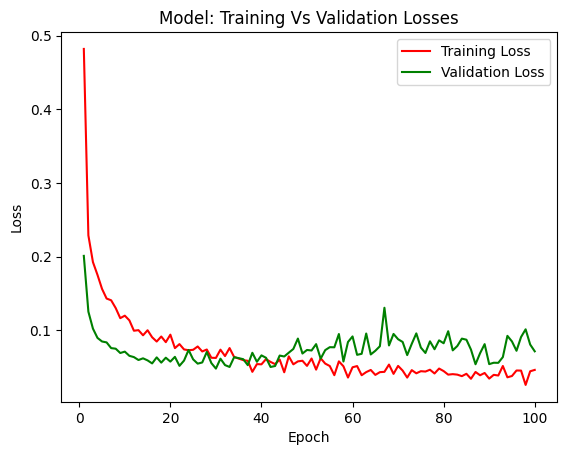

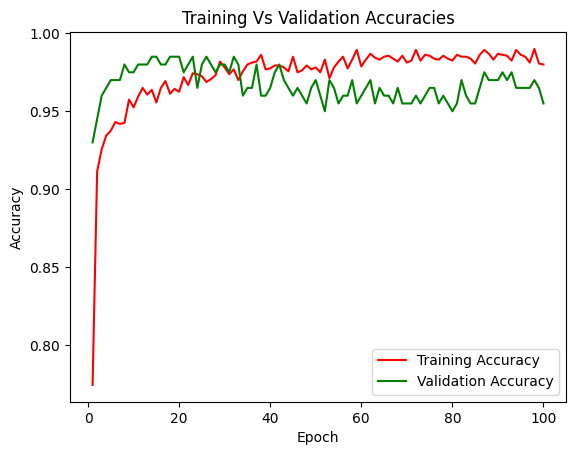

In [35]:
lossModel_Train = []
lossModel_val = []
accModel_Train = []
accModel_val = []

file = open(WeightPath + 'lossTrain.txt', 'r')
Testo = file.readlines()
for element in Testo:
  lossModel_Train.append(float(element))

file = open(WeightPath + 'lossVal.txt', 'r')
Testo = file.readlines()
for element in Testo:
  lossModel_val.append(float(element))

plt.figure()
plt.title("Model: Training Vs Validation Losses")
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.plot(list(range(1,len(lossModel_Train)+1)), lossModel_Train, color='r', label="Training Loss")
plt.plot(list(range(1, len(lossModel_val)+1)), lossModel_val, color='g', label="Validation Loss")
plt.legend()
plt.savefig(WeightPath + 'LossTrainVal.png')

file = open(WeightPath + 'AccTrain.txt', 'r')
Testo = file.readlines()
for element in Testo:
  accModel_Train.append(float(element))

file = open(WeightPath + 'AccVal.txt', 'r')
Testo = file.readlines()
for element in Testo:
  accModel_val.append(float(element))

plt.figure()
plt.title("Training Vs Validation Accuracies")
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.plot(list(range(1, len(accModel_Train)+1)), accModel_Train, color='r', label="Training Accuracy")
plt.plot(list(range(1, len(accModel_val)+1)), accModel_val, color='g', label="Validation Accuracy")
plt.legend()
plt.savefig(WeightPath + 'AccTrainVal.png')

In [ ]:
x = sio.loadmat(WeightPath + 'check_point.mat')
x

{'__header__': b'MATLAB 5.0 MAT-file Platform: posix, Created on: Thu May 22 19:14:38 2025',
 '__version__': '1.0',
 '__globals__': [],
 'best_acc': array([[0.99]]),
 'best_loss': array([[0.05649672]]),
 'best_epoca': array([[15]]),
 'last_epoch': array([[100]])}

# Prediction on test

In [36]:
from PIL import Image
set_classes_number = 2
#Mi serve la sample_submission solo per prendere gli ID delle immagini di test
#da caricare e da dare in input alla rete
Test = pd.DataFrame()

classes = ['dogs', 'wolves']

model_conv = torchvision.models.alexnet(pretrained=True)
model_conv.classifier[6] = nn.Linear(4096, set_classes_number)
model_conv.load_state_dict(torch.load(WeightPath + '/best_model_weights.pth'))
model_conv = model_conv.cuda()
model_conv.eval()


data_transforms = transforms.Compose([
                                      transforms.Resize(256),
                                      transforms.CenterCrop(224),
                                      transforms.ToTensor(),
                                      transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
                                      ])

listImage = test_file.files
prediction = []
for input in listImage:
  print('Working on '+ input)
  img = Image.open(path_test + input)
  img = data_transforms(img).to(device)
  img = img.unsqueeze_(0)
  outputs = model_conv(img)
  _, predicted = torch.max(outputs, 1)
  prediction.append(classes[predicted.item()])


test_file['prediction'] = prediction

/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Working on n02107908_4301.jpg
Working on n02108089_3162.jpg
Working on n02108915_1612.jpg
Working on n02102480_4769.jpg
Working on n02101006_2918.jpg
Working on n02096051_1912.jpg
Working on n02095314_740.jpg
Working on n02113712_2552.jpg
Working on n02091032_8093.jpg
Working on n02110806_1179.jpg
Working on n02094258_1132.jpg
Working on n02090721_3564.jpg
Working on n02086240_5554.jpg
Working on n02111277_4292.jpg
Working on n02099267_3018.jpg
Working on n02101556_7923.jpg
Working on n02088364_14079.jpg
Working on n02091032_8428.jpg
Working on n02093859_3394.jpg
Working on n02090622_5956.jpg
Working on n02108915_1895.jpg
Working on n02104365_7065.jpg
Working on n02097298_8452.jpg
Working on n02100735_4912.jpg
Working on n02107142_4148.jpg
Working on n02102177_967.jpg
Working on n02104029_986.jpg
Working on n02113712_3109.jpg
Working on n02106166_7074.jpg
Working on n02099712_5338.jpg
Working on n02089973_3604.jpg
Working on n02089867_3436.jpg
Working on n02115641_8150.jpg
Working on n

In [37]:
true_label = test_file.label.values
predicted = test_file.prediction.values
print((np.sum((true_label == predicted).astype(int)))/test_file.shape[0])

0.975


<Axes: >

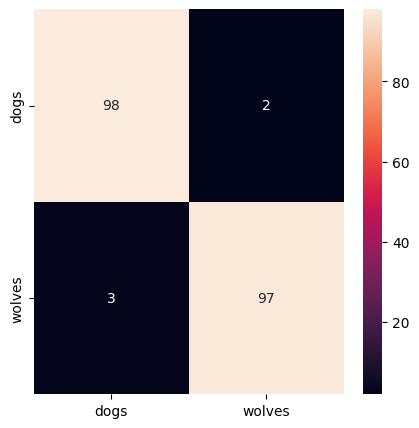

In [38]:
from sklearn.metrics import confusion_matrix
import seaborn as sn

c = confusion_matrix(true_label,predicted, labels=classes)
df_cm = pd.DataFrame(c , index = [i for i in classes],
                  columns = [i for i in classes])
plt.figure(figsize = (5,5))
sn.heatmap(df_cm, annot=True)

# Explainability

In [ ]:
!pip install captum

In [ ]:
from PIL import Image
from captum.attr import IntegratedGradients
from captum.attr import Saliency
from captum.attr import DeepLift
from captum.attr import NoiseTunnel
from captum.attr import GuidedGradCam
from captum.attr import LayerGradCam
from captum.attr import visualization as viz
from captum.attr import Occlusion
from captum.attr import GradientShap
from matplotlib.colors import LinearSegmentedColormap


networkName = 'alexnet16_onlyLast'
WeightPath = '/content/gdrive/My Drive/MASTER_2024_2025/' + networkName + '/'

data_transforms_1 = transforms.Compose([
                                      transforms.Resize(256),
                                      transforms.CenterCrop(224),
                                      transforms.ToTensor(),
                                      #transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
                                      ])
data_transforms_2 = transforms.Compose([ transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
                                      ])

def attribute_image_features(algorithm, input, label, **kwargs):
    tensor_attributions = algorithm.attribute(input,
                                              target=label, **kwargs
                                             )

    return tensor_attributions



set_classes_number = 2
#Mi serve la sample_submission solo per prendere gli ID delle immagini di test
#da caricare e da dare in input alla rete
Test = pd.DataFrame()

classes = ['dogs', 'wolves']

model_conv = torchvision.models.alexnet(pretrained=True)
model_conv.classifier[6] = nn.Linear(4096, set_classes_number)
model_conv.load_state_dict(torch.load(WeightPath + '/best_model_weights.pth'))
model_conv = model_conv.cuda()
model_conv.eval()
f = nn.Softmax(dim=1)

listImage = test_file.files
label = test_file.label.values
idx = 120

input = listImage[idx]
img = Image.open(path_test + input)
original_image = img.copy()
original_image = data_transforms_1(img)
img = data_transforms_2(original_image).to(device)
img = img.unsqueeze_(0)
outputs = model_conv(img)
_, predicted = torch.max(outputs, 1)

print('Predicted ' + classes[predicted] + '  REAL: ' + label[idx])


original_image = np.transpose(original_image.cpu().detach().numpy(), (1, 2, 0))

Predicted wolves  REAL: wolves


**Gradient-weighted Class Activation Mapping (Grad-CAM)**, uses the gradients of any target concept (say ‘dog’ in a classification network or a sequence of words in captioning network) flowing into the final convolutional layer to produce a coarse localization map highlighting the important regions in the image for predicting the concept.

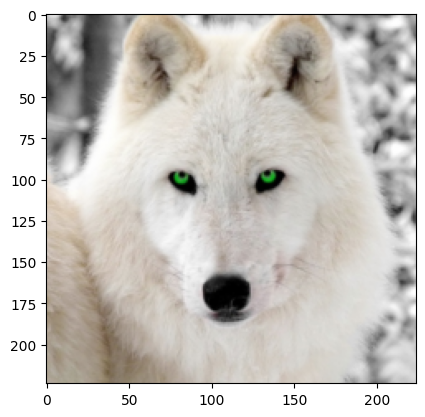

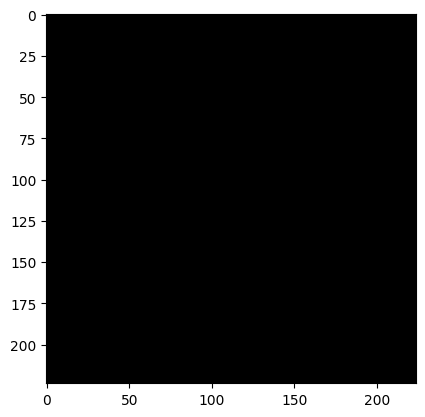

In [ ]:
guided_gc = GuidedGradCam(model_conv, model_conv.features[12])
attribution = guided_gc.attribute(img,  classes.index('dogs'))  #classes.index(label[idx])
attribution = attribution.squeeze(0).cpu().detach().numpy().transpose((1,2,0))
heatmap = np.uint8(255 *attribution)

plt.imshow(original_image)
plt.show()

plt.imshow(heatmap, cmap='BuGn')
plt.show()


**Saliency:** A baseline approach for computing input attribution. It returns the gradients with respect to inputs.

In [ ]:
saliency = Saliency(model_conv)
grads = saliency.attribute(img, target=classes.index('wolves'))
grads = np.transpose(grads.squeeze().cpu().detach().numpy(), (1, 2, 0))

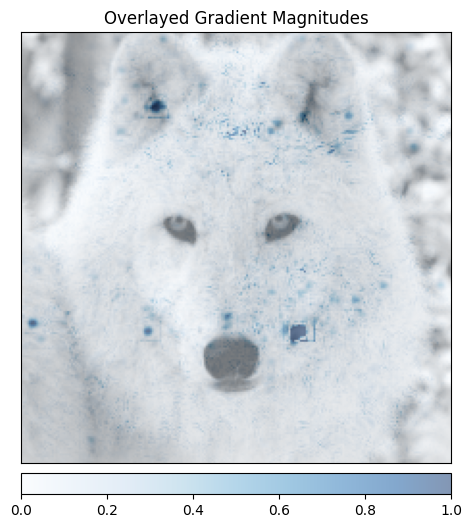

In [ ]:
#wolves
_ = viz.visualize_image_attr(grads, original_image, method="blended_heat_map", sign="absolute_value",
                          show_colorbar=True, title="Overlayed Gradient Magnitudes")

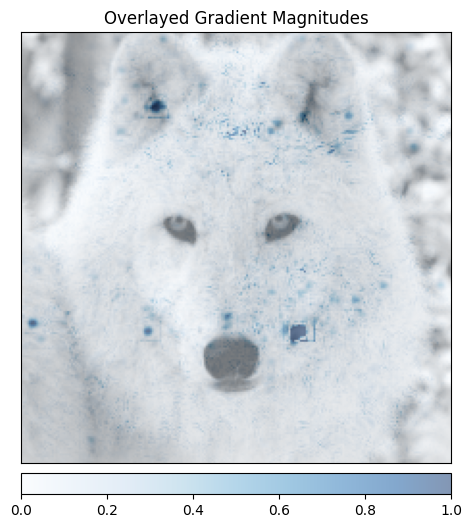

In [ ]:
#dogs
_ = viz.visualize_image_attr(grads, original_image, method="blended_heat_map", sign="absolute_value",
                          show_colorbar=True, title="Overlayed Gradient Magnitudes")

**Integrated Gradients** is an axiomatic model interpretability algorithm that assigns an importance score to each input feature by approximating the integral of gradients of the model’s output with respect to the inputs along the path (straight line) from given baselines / references to inputs.

Approximation delta:  tensor([0.1778], device='cuda:0', dtype=torch.float64)


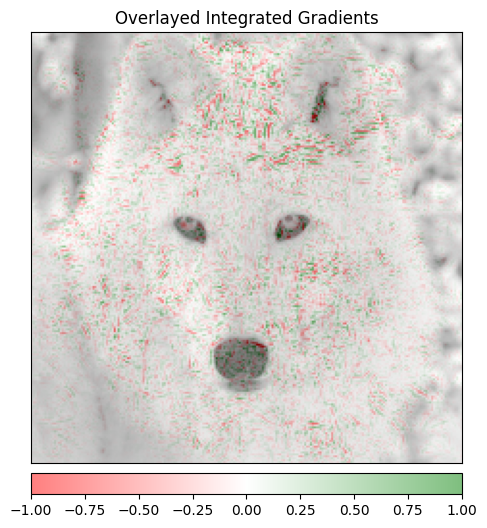

In [ ]:
ig = IntegratedGradients(model_conv)
attr_ig, delta = attribute_image_features(ig, img, classes.index('wolves'), baselines=img * 0, return_convergence_delta=True)
attr_ig = np.transpose(attr_ig.squeeze().cpu().detach().numpy(), (1, 2, 0))
print('Approximation delta: ', abs(delta))

_ = viz.visualize_image_attr(attr_ig, original_image, method="blended_heat_map",sign="all",
                          show_colorbar=True, title="Overlayed Integrated Gradients")

In [ ]:
ig = IntegratedGradients(model_conv)
attr_ig, delta = attribute_image_features(ig, img, classes.index('dogs'), baselines=img * 0, return_convergence_delta=True)
attr_ig = np.transpose(attr_ig.squeeze().cpu().detach().numpy(), (1, 2, 0))
print('Approximation delta: ', abs(delta))

_ = viz.visualize_image_attr(attr_ig, original_image, method="blended_heat_map",sign="all",
                          show_colorbar=True, title="Overlayed Integrated Gradients")

**Occlusion method:** A perturbation based approach to compute attribution, involving replacing each contiguous rectangular region with a given baseline / reference, and computing the difference in output. For features located in multiple regions (hyperrectangles), the corresponding output differences are averaged to compute the attribution for that feature.

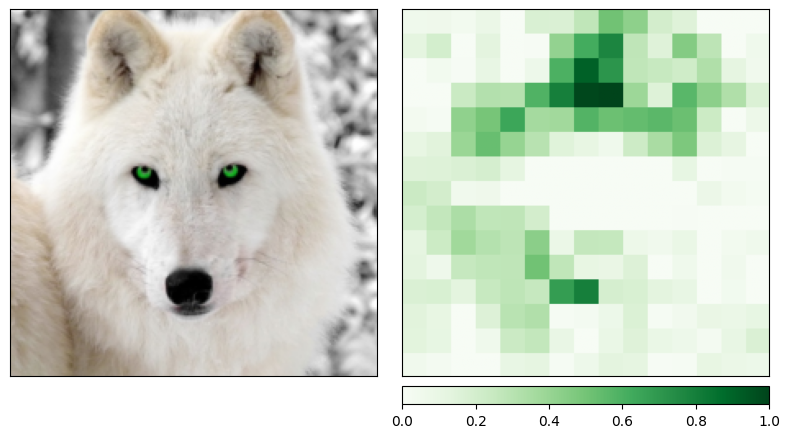

In [ ]:
occlusion = Occlusion(model_conv)

attributions_occ = occlusion.attribute(img,
                                       strides = (3, 15, 15),
                                       target=classes.index(label[idx]),
                                       sliding_window_shapes=(3,15, 15),
                                       baselines=0)


_ = viz.visualize_image_attr_multiple(np.transpose(attributions_occ.squeeze().cpu().detach().numpy(), (1,2,0)),
                                      original_image,
                                      ["original_image", "heat_map"],
                                      ["all", "positive"],
                                      show_colorbar=True,
                                      outlier_perc=2)

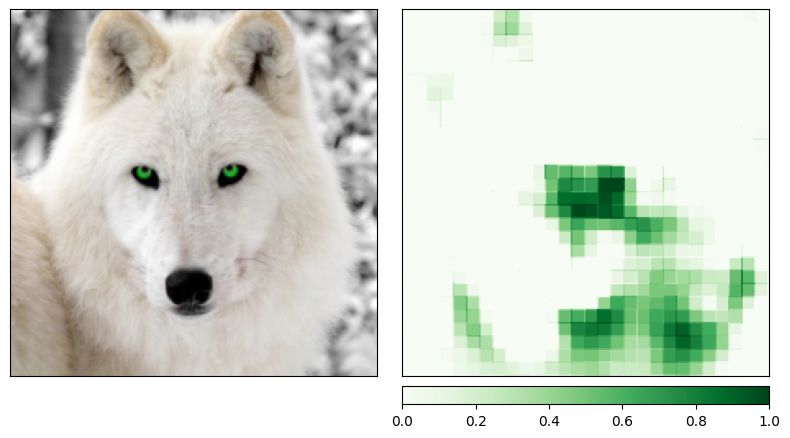

In [ ]:

attributions_occ = occlusion.attribute(img,
                                       strides = (3, 8, 8),
                                       target=classes.index('dogs'),
                                       sliding_window_shapes=(3,15, 15),
                                       baselines=0)


_ = viz.visualize_image_attr_multiple(np.transpose(attributions_occ.squeeze().cpu().detach().numpy(), (1,2,0)),
                                      original_image,
                                      ["original_image", "heat_map"],
                                      ["all", "positive"],
                                      show_colorbar=True,
                                      outlier_perc=2)